<a id='1'></a><center> <h3 style="background-color:orange; color:white" ><br>Excel Basics: Cell Referencing & Sales Analytics<br></h3></center>

# Introduction
This Jupyter notebook is part of your learning experience in foundational spreadsheet modeling, formula design, and cell referencing architectures. In this assignment, you will analyze retail fruit sales transactions, implement and compare Relative, Absolute, and Mixed cell referencing mechanics, compute discounted revenue liabilities, and evaluate transactional performance.

### Key Objectives:
1. **Spreadsheet Referencing Paradigms**:
   - **Relative Cell Reference** (`B2*C2`): Dynamic displacement along both rows and columns.
   - **Absolute Cell Reference** (`E2*($F$9/100)`): Anchoring fixed parameter cells (18% corporate discount rate) across all evaluations.
   - **Mixed Cell Reference** (`=$E2-$F2`): Locking dimensional columns while preserving relative row movement.
2. **Transactional Calculations**:
   - Formulate Total Sales, Discount Value, and Net Realized Revenue across fruit categories.
3. **Summary & Contribution Modeling**:
   - Compute total volume, average unit pricing, aggregate discount deductions, and product revenue contributions.
4. **Visual Intelligence**:
   - Render multi-panel visual representations comparing gross volume, discount absorption, and category market shares.

---
## Task 1 - Environment Setup & Dataset Ingestion

Load core data science packages (`pandas`, `numpy`, `matplotlib`, `seaborn`) and ingest the sales transaction dataset (`Fruit_Sales_Referencing_Data.csv`).

In [1]:
# Import analytical packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')

# Set aesthetic styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Ingest dataset
df = pd.read_csv('Fruit_Sales_Referencing_Data.csv')
print(f"Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns")
print("\nTransactional Fruit Sales Records:")
display(df)


Dataset Shape: 5 rows × 7 columns

Transactional Fruit Sales Records:


,Fruits,Quantity,Unit Price,Date Sold,Total Sales,Discount Value,Net Sales
0,Apples,10,15,2024-06-01,150.0,27.00,123.00
1,Bananas,15,10,2024-06-02,150.0,27.00,123.00
2,Cherries,7,12,2024-06-03,84.0,15.12,68.88
3,Dates,20,18,2024-06-04,360.0,64.80,295.20
4,Oranges,5,14,2024-06-05,70.0,12.60,57.40


---
## Task 2 - Cell Referencing Taxonomy & Mathematical Mechanics

Spreadsheet modeling relies on three distinct referencing mechanisms:

| Reference Type | Example Formula | Row Behavior | Column Behavior | Application in Project |
| :--- | :---: | :---: | :---: | :--- |
| **Relative** | `=B2*C2` | Shifts relatively (`B3*C3`) | Shifts relatively (`C2*D2`) | Computing **Total Sales** (`Quantity * Unit Price`) |
| **Absolute** | `=E2*($F$9/100)` | Fixed at Row 9 (`$9`) | Fixed at Column F (`$F`) | Computing **Discount Value** using fixed rate cell `$F$9` (18%) |
| **Mixed** | `=$E2-$F2` | Shifts relatively (`2` $\rightarrow$ `3`) | Fixed at Columns E & F (`$E`, `$F`) | Computing **Net Sales** (`Total Sales - Discount Value`) |

In [2]:
# Verification of referencing mathematical outputs
discount_rate = 0.18 # Fixed parameter equivalent to cell $F$9

# 1. Relative: Quantity * Unit Price
computed_total = df['Quantity'] * df['Unit Price']

# 2. Absolute: Total Sales * Fixed Rate
computed_discount = np.round(computed_total * discount_rate, 2)

# 3. Mixed: Total Sales - Discount Value
computed_net = np.round(computed_total - computed_discount, 2)

parity_check = (
    np.allclose(df['Total Sales'], computed_total) and
    np.allclose(df['Discount Value'], computed_discount) and
    np.allclose(df['Net Sales'], computed_net)
)

print(f"Mathematical & Formula Parity Confirmed: {parity_check} ✅")


Mathematical & Formula Parity Confirmed: True ✅


---
## Task 3 - Category Performance & Revenue Contribution

We aggregate transaction volume and evaluate individual fruit lines by:
- **Share of Total Units**: Proportional volume velocity.
- **Share of Net Sales**: Total dollar contribution to realized revenue.

In [3]:
# Compute contribution shares
df_summary = df.copy()
grand_total_net = df_summary['Net Sales'].sum()
grand_total_qty = df_summary['Quantity'].sum()

df_summary['Qty Share %'] = np.round((df_summary['Quantity'] / grand_total_qty) * 100, 2)
df_summary['Revenue Share %'] = np.round((df_summary['Net Sales'] / grand_total_net) * 100, 2)

# Sort by Net Sales descending
df_summary = df_summary.sort_values(by='Net Sales', ascending=False).reset_index(drop=True)

# Generate Grand Total Summary Row
total_row = pd.DataFrame({
    'Fruits': ['Total'],
    'Quantity': [grand_total_qty],
    'Unit Price': [df_summary['Unit Price'].mean()],
    'Date Sold': ['-'],
    'Total Sales': [df_summary['Total Sales'].sum()],
    'Discount Value': [df_summary['Discount Value'].sum()],
    'Net Sales': [grand_total_net],
    'Qty Share %': [100.00],
    'Revenue Share %': [100.00]
})

df_display = pd.concat([df_summary, total_row], ignore_index=True)

print("=== Category Performance & Contribution Breakdown ===")
display(df_display.style.format({
    'Unit Price': '₹{:,.2f}',
    'Total Sales': '₹{:,.2f}',
    'Discount Value': '₹{:,.2f}',
    'Net Sales': '₹{:,.2f}',
    'Qty Share %': '{:.2f}%',
    'Revenue Share %': '{:.2f}%'
}))


=== Category Performance & Contribution Breakdown ===


,Fruits,Quantity,Unit Price,Date Sold,Total Sales,Discount Value,Net Sales,Qty Share %,Revenue Share %
0,Dates,20,₹18.00,2024-06-04,₹360.00,₹64.80,₹295.20,35.09%,44.23%
1,Apples,10,₹15.00,2024-06-01,₹150.00,₹27.00,₹123.00,17.54%,18.43%
2,Bananas,15,₹10.00,2024-06-02,₹150.00,₹27.00,₹123.00,26.32%,18.43%
3,Cherries,7,₹12.00,2024-06-03,₹84.00,₹15.12,₹68.88,12.28%,10.32%
4,Oranges,5,₹14.00,2024-06-05,₹70.00,₹12.60,₹57.40,8.77%,8.60%
5,Total,57,₹13.80,-,₹814.00,₹146.52,₹667.48,100.00%,100.00%


---
## Task 4 - Visual Analytics Dashboard

We synthesize transaction metrics into a 4-panel visual dashboard:
1. **Gross vs. Net Realization**: Clustered bar chart highlighting discount absorption per category.
2. **Net Revenue Share**: Donut chart displaying product portfolio revenue distribution.
3. **Price vs. Quantity Positioning**: Scatter bubble chart analyzing volume velocity against pricing.
4. **Revenue Waterfall / Margin Retention**: Waterfall-style step reduction from Gross Total to Net Total.

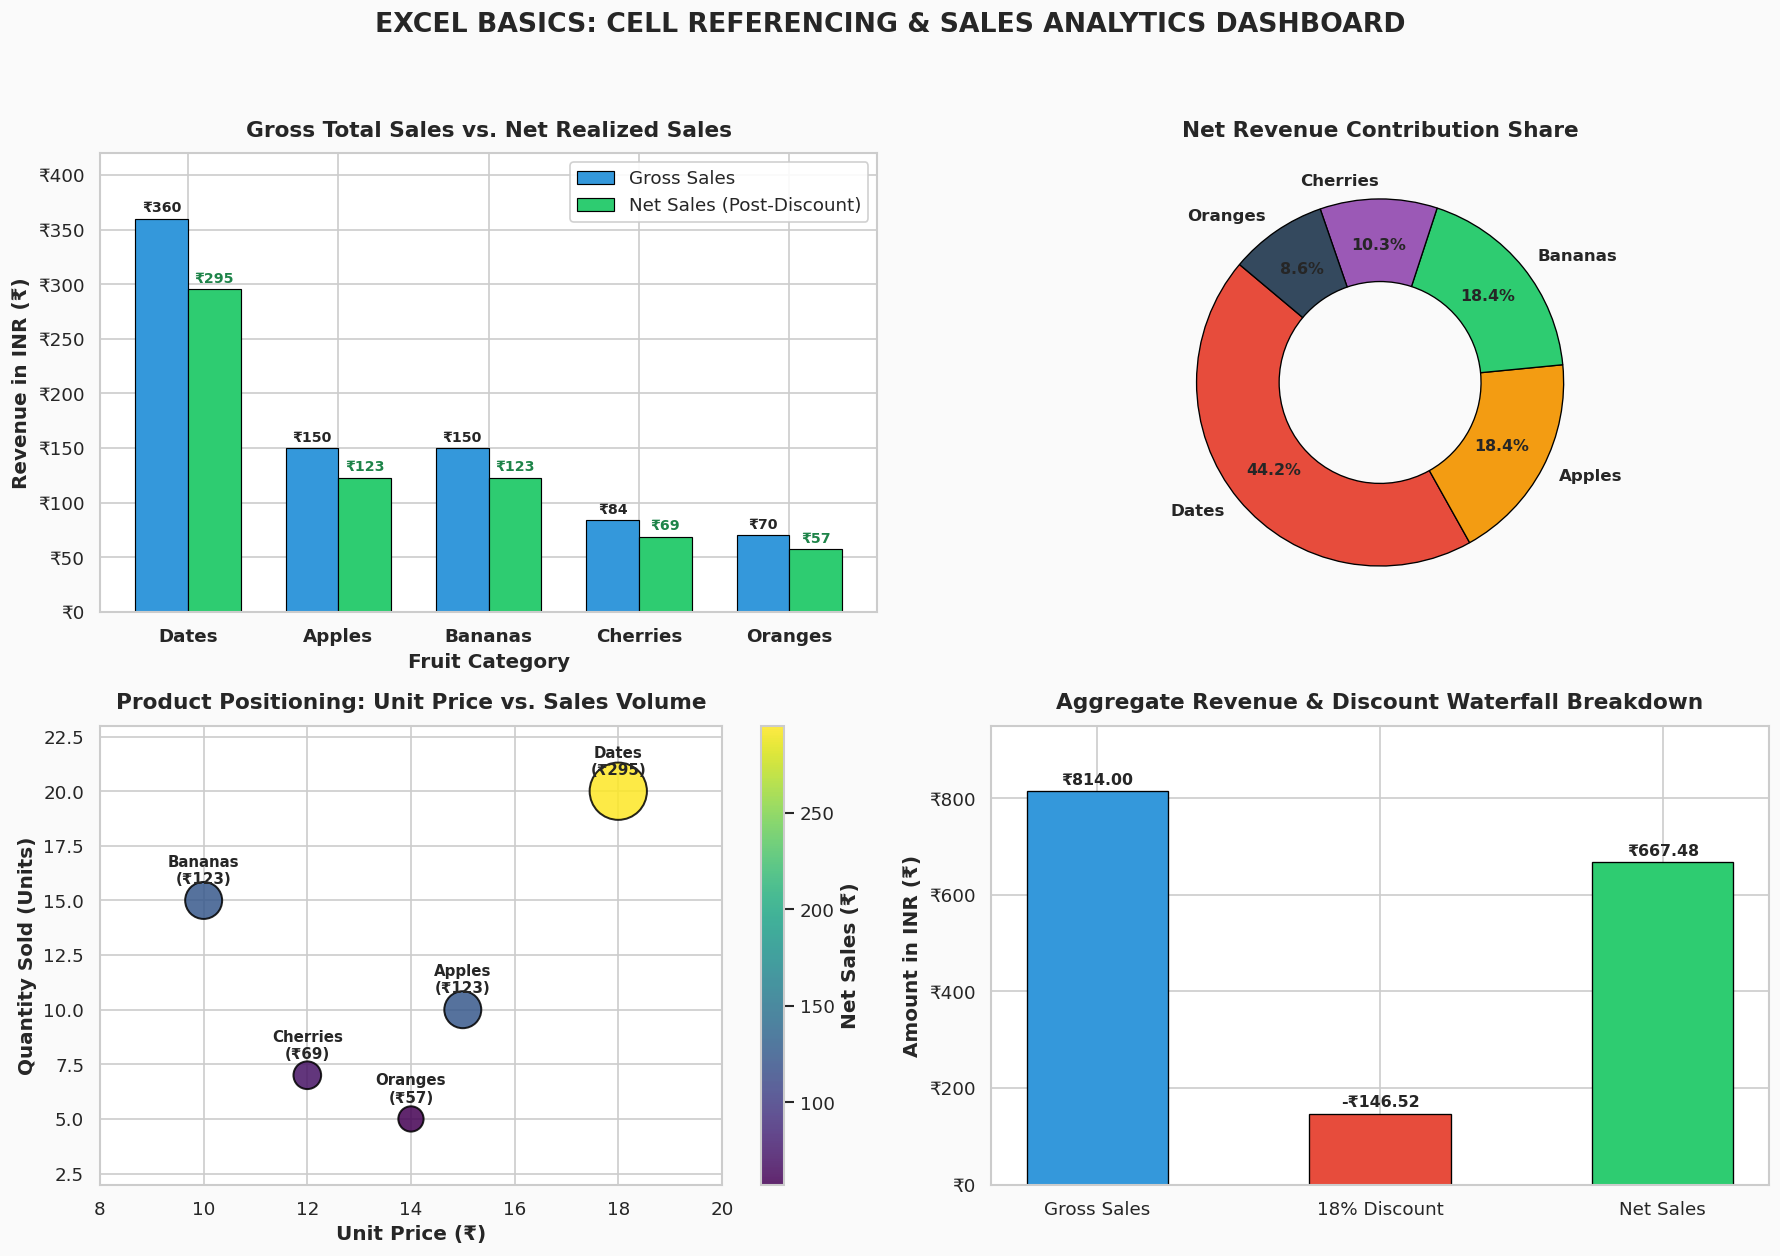

In [4]:
# Generate Visual Dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.patch.set_facecolor('#fafafa')

# 1. Top-Left: Gross vs. Net Sales
ax1 = axes[0, 0]
x = np.arange(len(df_summary))
width = 0.35
rects1 = ax1.bar(x - width/2, df_summary['Total Sales'], width, label='Gross Sales', color='#3498db', edgecolor='black', linewidth=0.7)
rects2 = ax1.bar(x + width/2, df_summary['Net Sales'], width, label='Net Sales (Post-Discount)', color='#2ecc71', edgecolor='black', linewidth=0.7)
ax1.set_title('Gross Total Sales vs. Net Realized Sales', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel('Fruit Category', fontweight='bold')
ax1.set_ylabel('Revenue in INR (₹)', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(df_summary['Fruits'], fontweight='bold')
ax1.yaxis.set_major_formatter('₹{x:,.0f}')
ax1.legend(frameon=True, facecolor='white', framealpha=0.9)
ax1.set_ylim(0, 420)

for r in rects1:
    h = r.get_height()
    ax1.annotate(f'₹{h:,.0f}', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 4), textcoords="offset points", ha='center', fontsize=8.5, fontweight='bold')
for r in rects2:
    h = r.get_height()
    ax1.annotate(f'₹{h:,.0f}', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 4), textcoords="offset points", ha='center', fontsize=8.5, fontweight='bold', color='#1e8449')

# 2. Top-Right: Net Revenue Share Donut Chart
ax2 = axes[0, 1]
colors_pie = ['#e74c3c', '#f39c12', '#2ecc71', '#9b59b6', '#34495e']
wedges, texts, autotexts = ax2.pie(
    df_summary['Net Sales'],
    labels=df_summary['Fruits'],
    autopct='%1.1f%%',
    pctdistance=0.75,
    startangle=140,
    colors=colors_pie,
    wedgeprops=dict(width=0.45, edgecolor='black', linewidth=0.8)
)
for t in texts:
    t.set_fontsize(10)
    t.set_fontweight('bold')
for at in autotexts:
    at.set_fontsize(9.5)
    at.set_fontweight('bold')
ax2.set_title('Net Revenue Contribution Share', fontsize=13, fontweight='bold', pad=10)

# 3. Bottom-Left: Price vs Quantity Matrix
ax3 = axes[1, 0]
scatter = ax3.scatter(
    df_summary['Unit Price'], 
    df_summary['Quantity'], 
    s=df_summary['Net Sales'] * 4, 
    c=df_summary['Net Sales'], 
    cmap='viridis', 
    alpha=0.85, 
    edgecolors='black', 
    linewidth=1.2
)
ax3.set_title('Product Positioning: Unit Price vs. Sales Volume', fontsize=13, fontweight='bold', pad=10)
ax3.set_xlabel('Unit Price (₹)', fontweight='bold')
ax3.set_ylabel('Quantity Sold (Units)', fontweight='bold')
ax3.set_xlim(8, 20)
ax3.set_ylim(2, 23)

for _, row in df_summary.iterrows():
    ax3.annotate(f"{row['Fruits']}\n(₹{row['Net Sales']:,.0f})", 
                 xy=(row['Unit Price'], row['Quantity']),
                 xytext=(0, 10), textcoords="offset points",
                 ha='center', fontsize=9, fontweight='bold')

cbar = plt.colorbar(scatter, ax=ax3)
cbar.set_label('Net Sales (₹)', fontweight='bold')

# 4. Bottom-Right: Waterfall Breakdown
ax4 = axes[1, 1]
stages = ['Gross Sales', '18% Discount', 'Net Sales']
values = [df_summary['Total Sales'].sum(), -df_summary['Discount Value'].sum(), df_summary['Net Sales'].sum()]
colors_wf = ['#3498db', '#e74c3c', '#2ecc71']
bars_wf = ax4.bar(stages, [values[0], abs(values[1]), values[2]], color=colors_wf, edgecolor='black', linewidth=0.8, width=0.5)
ax4.set_title('Aggregate Revenue & Discount Waterfall Breakdown', fontsize=13, fontweight='bold', pad=10)
ax4.set_ylabel('Amount in INR (₹)', fontweight='bold')
ax4.yaxis.set_major_formatter('₹{x:,.0f}')
ax4.set_ylim(0, 950)

for bar, val in zip(bars_wf, values):
    h = bar.get_height()
    prefix = '-' if val < 0 else ''
    ax4.annotate(f'{prefix}₹{abs(val):,.2f}', xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 4), textcoords="offset points", ha='center', fontsize=9.5, fontweight='bold')

plt.suptitle('EXCEL BASICS: CELL REFERENCING & SALES ANALYTICS DASHBOARD', fontsize=16, fontweight='heavy', y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


---
## Task 5 - Key Takeaways & Spreadsheet Engineering Insights

### 1. Cell Referencing Best Practices:
- **Relative Referencing (`B2*C2`)**: Essential for row-by-row transactional computing where operators must track shifting records dynamically.
- **Absolute Referencing (`$F$9`)**: Essential for global parameters (tax rates, discount percentages, commission schedules) to eliminate parameter drift.
- **Mixed Referencing (`=$E2-$F2`)**: Locks the column while allowing row freedom, safeguarding multi-dimensional matrix cross-calculations.

### 2. Commercial Category Findings:
- **Top Contributor**: **Dates** generated **₹295.20** in net sales (**44.23%** of total revenue), driven by highest unit price (₹18) and highest quantity (20 units).
- **Secondary Tier**: **Apples** and **Bananas** contributed **₹123.00** each (**18.43%** each), demonstrating high volume velocity.
- **Niche Tier**: **Cherries** (₹68.88, **10.32%**) and **Oranges** (₹57.40, **8.60%**) represent lower volume lines with growth potential.

### 3. Financial Aggregate Summary:
- **Gross Sales Generated**: **₹814.00**
- **Total Promotional Discount Disbursed (18%)**: **₹146.52**
- **Net Realized Revenue**: **₹667.48** (Net realization rate: **81.99%**).
